# Data & Func

In [1]:
from matplotlib import colors
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# nice plotting function with cartopy and coastlines. Use robinson projection
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.pyplot as plt
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.ticker import FixedLocator

# truncate a colormap. eg, lower half of a diverging cmap
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none' # to keep text as text in svg output

from pyfonts import load_google_font
#font = load_font('../fonts/InterVariable.ttf')
noto_font = load_google_font("Noto Sans")
OpenSans = load_google_font("Open Sans")
Inter = load_google_font("Inter")

# plotting function
def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', discrete_cmap=0, vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', cbar_loc = 'bottom', svg=False, grid_labels=False, local_map=False):
    
    if cmap_split=='low':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    elif cmap_split=='trim':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.1, 0.9)
    else:
        custom_cmap = plt.get_cmap(cmap)

    if discrete_cmap != 0:
        custom_cmap = discrete_colormap(custom_cmap, discrete_cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
        
    plt.figure(figsize=(12, 8))
    if local_map == False:
        ax = plt.axes(projection=ccrs.Robinson())
    else: # for local maps use PlateCarree projection
        ax = plt.axes(projection=ccrs.PlateCarree())
    # plot only nans in grey. supress cbar
    xr.where(dataarray.isnull(), 1, np.nan).plot(ax=ax, cmap=colors.ListedColormap(['lightgrey']), vmin=1, vmax=1, transform=ccrs.PlateCarree(), add_colorbar=False)
    # plot data
    dataarray.plot(ax=ax, cmap=custom_cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label, 'location': cbar_loc, 'fraction': 0.06, 'pad': 0.05, 'ticks': np.linspace(vmin + (vmin/discrete_cmap), vmax + (vmax/discrete_cmap), int((discrete_cmap + 1)/2)+1) if discrete_cmap else None}, transform=ccrs.PlateCarree())    
    ax.coastlines() # coastlines for context

    ax.add_feature(cf.OCEAN, facecolor='white', zorder=5)
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)

    if grid_labels:
        # show only major longitude/latitude labels using gridlines
        lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
        lat_ticks = [-45, -30, -15, 0, 15, 30, 45]

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0,
            x_inline=False,
            y_inline=False,
        )
        # show only bottom and left labels
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True
        gl.xlocator = FixedLocator(lon_ticks)
        gl.ylocator = FixedLocator(lat_ticks)
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}

    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

#discrete_colormap('viridis', 5)

# function for calculating glomal mean and std of a given dataarray, both weighted and unweighted
# weight by grid cell area calculated using earth's radius and latitude. i.e. create a weight array with same lat and lon dimensions as da, where weights = cos(lat) and then use xarray's weighted function to calculate mean and std
# area = R * (max_lat - min_lat) * (max_lon - min_lon) * cos(lat) where R is Earth's radius and lat is the latitude of the grid cell in radians.
# Since we are only interested in relative weights, we can ignore the constant R and the lat/lon differences and just use weights = cos(lat) for each grid cell.
def global_stats(da, weighted=True):
    if weighted:
        weights = np.cos(np.deg2rad(da['lat']))
        weighted_da = da.weighted(weights)
        mean = weighted_da.mean(dim=['lat', 'lon'])
        std = weighted_da.std(dim=['lat', 'lon'])
    else:
        mean = da.mean(dim=['lat', 'lon'])
        std = da.std(dim=['lat', 'lon'])
    return mean, std

In [2]:
preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked.zarr")
#sr_clim_1901_1930_LU_1901_1930 = preds.sel(climate='1901_1930', lu='1901_1930').sr_k6_mean
#sr_clim_1931_1960_LU_1931_1960 = preds.sel(climate='1931_1960', lu='1931_1960').sr_k6_mean

In [ ]:
preds

<xarray.Dataset> Size: 50GB
Dimensions:     (climate: 12, lu: 14, lat: 2600, lon: 7200)
Coordinates:
  * climate     (climate) <U16 768B '1901_1930' ... '2071_2099_ssp460'
  * lu          (lu) <U16 896B 'intact' 'pre-industrial' ... '2071_2099_ssp460'
  * lat         (lat) float64 21kB -55.58 -55.52 -55.48 ... 74.28 74.33 74.38
  * lon         (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Data variables:
    sr_k0_mean  (climate, lu, lat, lon) float32 13GB ...
    sr_k0_std   (climate, lu, lat, lon) float32 13GB ...
    sr_k6_mean  (climate, lu, lat, lon) float32 13GB ...
    sr_k6_std   (climate, lu, lat, lon) float32 13GB ...

In [7]:
sr_clim_1901_1930_LU_1901_1930

<xarray.DataArray 'sr_k6_mean' (lat: 2600, lon: 7200)> Size: 75MB
[18720000 values with dtype=float32]
Coordinates:
  * lat      (lat) float64 21kB -55.58 -55.52 -55.48 ... 74.28 74.33 74.38
  * lon      (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    climate  <U16 64B '1901_1930'
    lu       <U16 64B '1901_1930'

In [11]:
sr_clim_1901_1930_LU_1901_1930.rename('sr').drop_vars(['climate', 'lu']).to_netcdf("../export/sr_1901_1930.nc")
sr_clim_1931_1960_LU_1931_1960.rename('sr').drop_vars(['climate', 'lu']).to_netcdf("../export/sr_1931_1960.nc")

In [ ]:
# load data
sr_target = xr.open_dataarray("../data/SR-target/merged_SR.nc")
#preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked_squarederror.zarr")
preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked.zarr")
nanMask = xr.where(np.isfinite(preds.sr_k0_mean.isel(climate = 0, lu = 0)), np.nan, 1).drop_vars(['climate', 'lu']) # mask with value 1 for missing data

sr_clim_1901_1930_LU_PI = preds.sel(climate='1901_1930', lu='pre-industrial').sr_k6_mean
sr_clim_1901_1930_LU_1901_1930 = preds.sel(climate='1901_1930', lu='1901_1930').sr_k6_mean
sr_clim_1901_1930_LU_1991_2020 = preds.sel(climate='1901_1930', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_PI = preds.sel(climate='1991_2020', lu='pre-industrial').sr_k6_mean
sr_clim_1991_2020_LU_1901_1930 = preds.sel(climate='1991_2020', lu='1901_1930').sr_k6_mean
sr_clim_1991_2020_LU_1991_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
sr_clim_1991_2020_LU_Intact = preds.sel(climate='1991_2020', lu='intact').sr_k6_mean
sr_clim_1961_1990_LU_1961_1990 = preds.sel(climate='1961_1990', lu='1961_1990').sr_k6_mean
sr_clim_1931_1960_LU_1931_1960 = preds.sel(climate='1931_1960', lu='1931_1960').sr_k6_mean
deltaSR_Intact_to_Present = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_PI = sr_clim_1901_1930_LU_PI - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_1901 = sr_clim_1901_1930_LU_1901_1930 - sr_clim_1901_1930_LU_Intact
deltaSR_PI_to_1901 = sr_clim_1901_1930_LU_1901_1930 - sr_clim_1901_1930_LU_PI
deltaSR_20thC = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_clim = sr_clim_1991_2020_LU_1901_1930 - sr_clim_1901_1930_LU_1901_1930
deltaSR_LU = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_interaction = deltaSR_20thC - deltaSR_clim - deltaSR_LU
deltaSR_pnv = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1991_2020_LU_Intact
deltaSR_recent = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1961_1990_LU_1961_1990

# create a grid area array for weighting.
# It has the area in square kilometers for each grid cell, calculated using the formula: area = R^2 * (lon2 - lon1) * (sin(lat2) - sin(lat1)),
# where R is Earth's radius (6371 km), lat1 and lat2 are the latitudes of the grid cell edges in radians,
# and lon1 and lon2 are the longitudes of the grid cell edges in radians.
R = 6371  # Earth's radius in kilometers
lat_edges = np.deg2rad(sr_target['lat'].values)  # convert latitudes to radians
lon_edges = np.deg2rad(sr_target['lon'].values)  # convert longitudes to radians
lat1 = lat_edges - np.deg2rad(0.05/2) # assuming 0.05 degree grid cells, calculate the edges
lat2 = lat_edges + np.deg2rad(0.05/2)
lon1 = lon_edges - np.deg2rad(0.05/2)
lon2 = lon_edges + np.deg2rad(0.05/2)
# create 2d arrays for lat1, lat2, lon1, lon2 to match the dimensions of the grid
lat1_2d, lon1_2d = np.meshgrid(lat1, lon1, indexing='ij')
lat2_2d, lon2_2d = np.meshgrid(lat2, lon2, indexing='ij')
area = R**2 * (lon2_2d - lon1_2d) * (np.sin(lat2_2d) - np.sin(lat1_2d))  # area in square kilometers
area_da = xr.DataArray(area, coords=sr_target.coords, dims=sr_target.dims, name='grid_cell_area')
#plot_map(area_da, title='Grid Cell Area', cmap='viridis', cbar_label='Area (sq km)', grid_labels=True)

pct_deltaSR = deltaSR_20thC/sr_clim_1901_1930_LU_PI * 100
abs_pct_deltaSR = np.abs(pct_deltaSR)

# global means using the global_stats function
deltaSR_20thC_mean, deltaSR_20thC_std = global_stats(deltaSR_20thC, weighted=True)
deltaSR_Intact_to_PI_mean, deltaSR_Intact_to_PI_std = global_stats(deltaSR_Intact_to_PI, weighted=True)
deltaSR_Intact_to_1901_mean, deltaSR_Intact_to_1901_std = global_stats(deltaSR_Intact_to_1901, weighted=True)
deltaSR_PI_to_1901_mean, deltaSR_PI_to_1901_std = global_stats(deltaSR_PI_to_1901, weighted=True)
deltaSR_Intact_to_Present_mean, deltaSR_Intact_to_Present_std = global_stats(deltaSR_Intact_to_Present, weighted=True)
deltaSR_clim_mean, deltaSR_clim_std = global_stats(deltaSR_clim, weighted=True)
deltaSR_LU_mean, deltaSR_LU_std = global_stats(deltaSR_LU, weighted=True)
deltaSR_interaction_mean, deltaSR_interaction_std = global_stats(deltaSR_interaction, weighted=True)
abs_pct_deltaSR_mean = global_stats(abs_pct_deltaSR, weighted=True)
deltaSR_pnv_mean, deltaSR_pnv_std = global_stats(deltaSR_pnv, weighted=True)
deltaSR_recent_mean, deltaSR_recent_std = global_stats(deltaSR_recent, weighted=True)

In [3]:
# aggregate by biome
# load TEOW biome 0.05 raster
biome = xr.open_dataarray("../data/TEOW_biomes.nc")
# assign 0 to nans and convert to int
biome = xr.where(np.isfinite(biome), biome, 0).astype(int)
ocean = xr.where(biome == 0, 1, np.nan)

# create biomeStat xarray dataset
# make biome a dimension and the coordinates are the unique biome values.
# Then add the other variables as data variables
biomeStats_ds = xr.Dataset(
    data_vars={
        'biome': biome,
        'area': area_da,
        'SR_present': sr_clim_1991_2020_LU_1991_2020.rename('SR_present').drop_vars(['climate', 'lu']) * area_da, # weight by area for global sum
        'SR_PI': sr_clim_1901_1930_LU_PI.rename('SR_PI').drop_vars(['climate', 'lu']) * area_da, # weight by area for global sum
        'SR_intact': sr_clim_1901_1930_LU_Intact.rename('SR_intact').drop_vars(['climate', 'lu']) * area_da,
        'SR_1901': sr_clim_1901_1930_LU_1901_1930.rename('SR_1901').drop_vars(['climate', 'lu']) * area_da,
        'deltaSR_20thC' : deltaSR_20thC.rename('deltaSR_20thC') * area_da, # weight by area for global sum
        'deltaSR_clim' : deltaSR_clim.rename('deltaSR_clim').drop_vars(['lu']) * area_da,
        'deltaSR_LU' : deltaSR_LU.rename('deltaSR_LU').drop_vars(['climate']) * area_da,
        'pct_deltaSR': pct_deltaSR.rename('pct_deltaSR').drop_vars(['climate', 'lu']) * area_da
        },
    coords={
        'lat': biome['lat'],
        'lon': biome['lon']
    })

# units for SR cand deltaSR are in mm * square kilometers, which is equivalent to cubic kilometers.
# So we can convert to cubic kilometers by dividing by 1 million (since 1 cubic kilometer = 1 million cubic meters and 1 mm * 1 square kilometer = 1 million cubic meters).
# For percentage change, we can keep it as is since it's already a relative measure.

biome_ids = np.unique(biomeStats_ds['biome'].values)
vars_to_keep = ['SR_present', 'SR_PI', 'SR_intact', 'deltaSR_20thC', 
                'deltaSR_clim', 'deltaSR_LU', 'pct_deltaSR', 'area']

data_vars = {}
for var in vars_to_keep:
    # For each biome, keep values where biome matches, else NaN
    # biome_ids shape: (B,), ds[var] shape: (lat, lon)
    # Result shape: (lat, lon, biome)
    biome_mask = biomeStats_ds['biome'] == xr.DataArray(biome_ids, dims='biome')  # broadcasts to (lat, lon, biome)
    masked = biomeStats_ds[var].expand_dims(biome=biome_ids).where(biome_mask)
    data_vars[var] = masked

dsBiome = xr.Dataset(data_vars)

#weights = np.cos(np.deg2rad(dsBiome['lat']))
biomeStatsVol = dsBiome.groupby('biome').mean('lat').mean('lon').to_dataframe()
biomeStatsVolSum = dsBiome.groupby('biome').sum('lat').sum('lon').to_dataframe()
#biomeStats['area'] = dsBiome['area'].groupby('biome').sum('lat').sum('lon').values
# drop rows for biomes 0,98,99
biomeStatsVol = biomeStatsVol.drop(index=[0, 98, 99])
biomeStatsVolSum = biomeStatsVolSum.drop(index=[0, 98, 99])

# divide data variables by 1 million to convert from mm * square kilometers to cubic kilometers
for var in ['SR_present', 'SR_PI', 'SR_intact', 'deltaSR_20thC', 'deltaSR_clim', 'deltaSR_LU', 'pct_deltaSR']:
    biomeStatsVolSum[var] = biomeStatsVolSum[var] / 1e6

biomeStats = biomeStatsVol.copy()
for var in vars_to_keep:
    biomeStats[var] = biomeStats[var] / biomeStats['area'] # weight by area for global sum

In [4]:
error =sr_clim_1991_2020_LU_1991_2020 - sr_target
pct_error = (error / sr_target) * 100
normalized_error = error / sr_target.std(dim=['lat', 'lon'])

'''
# plot_map(error.coarsen(lat=5, lon=5).median(), vmin=-180, vmax=180, cmap='bwr', discrete_cmap=9, title='Error in $S_R$ Predictions (1991-2020)', cbar_label='Error (mm)')
# plot_map(pct_error.coarsen(lat=5, lon=5).median(), title='Percentage error in predicted $S_{R(1991-2020)}$ ', cmap='bwr', discrete_cmap=11, vmin=-110, vmax=110, borders=False, cbar_label='Percentage error %', grid_labels=False)

# histogram of error
plt.figure(figsize=(10, 6))
pct_error_vals = pct_error.values.flatten()
pct_error_vals = pct_error_vals[np.isfinite(pct_error_vals)]  # remove nans
plt.hist(pct_error_vals, bins=np.linspace(-150, 150, 151), color='skyblue', edgecolor=None)
plt.title('Percentage Error in $S_R$ Predictions (1991-2020)', fontsize=16)
#plt.yscale('log')  # use log scale for y axis to better show the distribution
plt.xlabel('Percentage Error (%)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(axis='y', alpha=0.75)
plt.show()

# predicted vs target as a 2D histogram
from matplotlib.colors import LogNorm
norm = LogNorm(vmin=1, vmax=5000) # log scale for better visibility of dense areas
# mutually mask the two arrays to ensure we only compare valid data points
valid_mask = np.isfinite(sr_target) & np.isfinite(deltaSR)
sr_target_valid = sr_target.where(valid_mask, drop=True)
sr_2020_valid = sr_2020.where(valid_mask, drop=True)
sr_target_flat = sr_target_valid.values.flatten()
sr_target_flat = sr_target_flat[~np.isnan(sr_target_flat)] # remove any remaining NaNs
sr_2020_flat = sr_2020_valid.values.flatten()
sr_2020_flat = sr_2020_flat[~np.isnan(sr_2020_flat)] # remove any remaining NaNs
# calc R2
r2 = np.corrcoef(sr_target_flat, sr_2020_flat)[0, 1]**2

plt.rcParams['font.size'] = 18
plt.figure(figsize=(8, 6))
plt.hist2d(sr_target_flat, sr_2020_flat, bins=5000, cmap='cubehelix', norm=norm) # log scale for better visibility
plt.colorbar(label='Count in bin')
plt.xlabel('Target $S_R$')
plt.ylabel('Predicted $S_R$')
plt.title('Predicted vs Target $S_R$')
plt.plot([0, 3000], [0, 3000], 'r--', linewidth=0.5) # 1:1 line for reference
# annotate R2 on the plot
plt.text(100, 2800, f'$R^2$ = {r2:.2f}', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.xlim(0, 3000)
plt.ylim(0, 3000)
plt.show()
'''

"\n# plot_map(error.coarsen(lat=5, lon=5).median(), vmin=-180, vmax=180, cmap='bwr', discrete_cmap=9, title='Error in $S_R$ Predictions (1991-2020)', cbar_label='Error (mm)')\n# plot_map(pct_error.coarsen(lat=5, lon=5).median(), title='Percentage error in predicted $S_{R(1991-2020)}$ ', cmap='bwr', discrete_cmap=11, vmin=-110, vmax=110, borders=False, cbar_label='Percentage error %', grid_labels=False)\n\n# histogram of error\nplt.figure(figsize=(10, 6))\npct_error_vals = pct_error.values.flatten()\npct_error_vals = pct_error_vals[np.isfinite(pct_error_vals)]  # remove nans\nplt.hist(pct_error_vals, bins=np.linspace(-150, 150, 151), color='skyblue', edgecolor=None)\nplt.title('Percentage Error in $S_R$ Predictions (1991-2020)', fontsize=16)\n#plt.yscale('log')  # use log scale for y axis to better show the distribution\nplt.xlabel('Percentage Error (%)', fontsize=14)\nplt.ylabel('Frequency', fontsize=14)\nplt.grid(axis='y', alpha=0.75)\nplt.show()\n\n# predicted vs target as a 2D histo

# 1. Global SR and Total Change

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

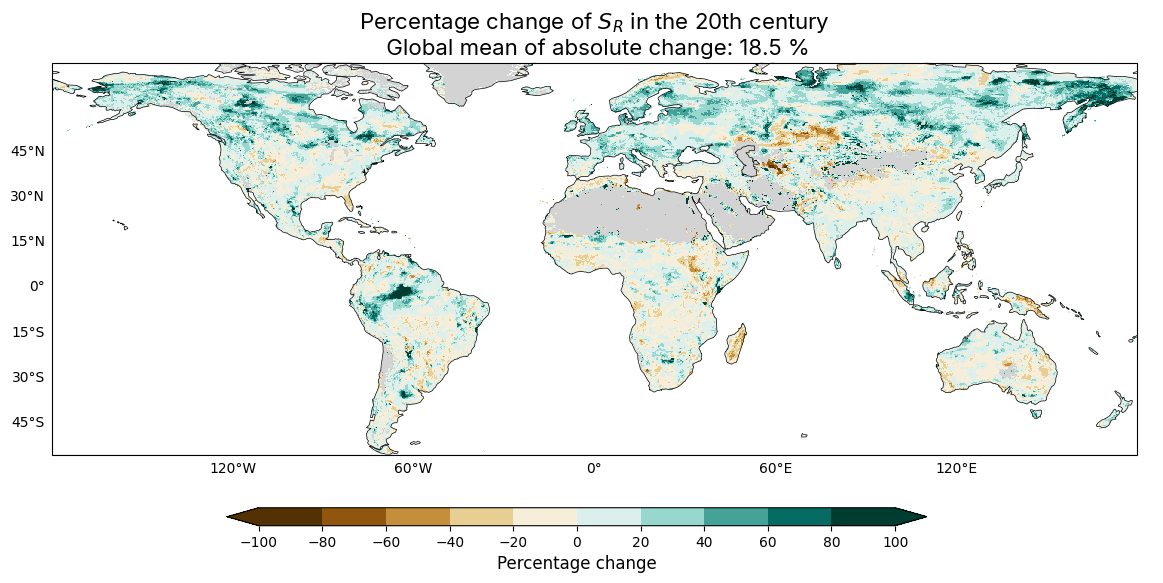

In [5]:
plt.rcParams['font.family'] = "Inter"
plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree()) # or robinson
daPlot = pct_deltaSR.coarsen(lat=5, lon=5).median() # coarsen for faster plotting
# 1. Plot only nans in grey (suppress cbar)
xr.where(daPlot.isnull(), 1, np.nan).plot(
    ax=ax, 
    cmap=colors.ListedColormap(['lightgrey']), 
    vmin=1, 
    vmax=1, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)
#Plot ovean over nans in white
ocean.coarsen(lat=5, lon=5).mean().plot(
    ax=ax, 
    cmap=colors.ListedColormap(['white']),
    vmin=1,
    vmax=1,
    transform=ccrs.PlateCarree(),
    add_colorbar=False
)

# 2. Plot data (store the plot object as 'im' and suppress automatic cbar)
im = daPlot.plot(
    ax=ax, 
    cmap=discrete_colormap('BrBG', 10), 
    vmin=-100, 
    vmax=100, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)

# 3. Create a dedicated axis for the horizontal colorbar below the plot
# Adjust the bottom positioning (0.05) so it doesn't overlap with the latitude labels
cax = plt.gcf().add_axes([0.25, 0.05, 0.5, 0.03]) # [left, bottom, width, height]

# 4. Generate the colorbar horizontally with explicit boundary ticks.
# control width and height of colorbar with cax, and set ticks to match the discrete colormap boundaries
cbar = plt.colorbar(
    im, 
    cax=cax, 
    orientation='horizontal', 
    #fraction=1,
    aspect=30,
    ticks=[-100, -80, -60, -40, -20, 0, 20, 40, 60, 80, 100],
    extend='both',
    pad=0.02

)
cbar.set_label('Percentage change', size=12)
cbar.ax.tick_params(labelsize=10)

# 5. Add context features
ax.coastlines(linewidth=0.5) # coastlines for context

# 6. Gridlines configuration
lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
lat_ticks = [-45, -30, -15, 0, 15, 30, 45]
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0,
    x_inline=False,
    y_inline=False,
)

# Show only bottom and left labels
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlocator = FixedLocator(lon_ticks)
gl.ylocator = FixedLocator(lat_ticks)
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

abs_pct_deltaSR_mean = global_stats(abs_pct_deltaSR, weighted=True)[0]
ax.set_title(f'Percentage change of $S_R$ in the 20th century \n Global mean of absolute change: {abs_pct_deltaSR_mean:.1f} %', font=Inter, fontsize=16)
#plt.savefig("../export/map_deltaSRmm.png", format='png', dpi=300, bbox_inches='tight')
plt.show()

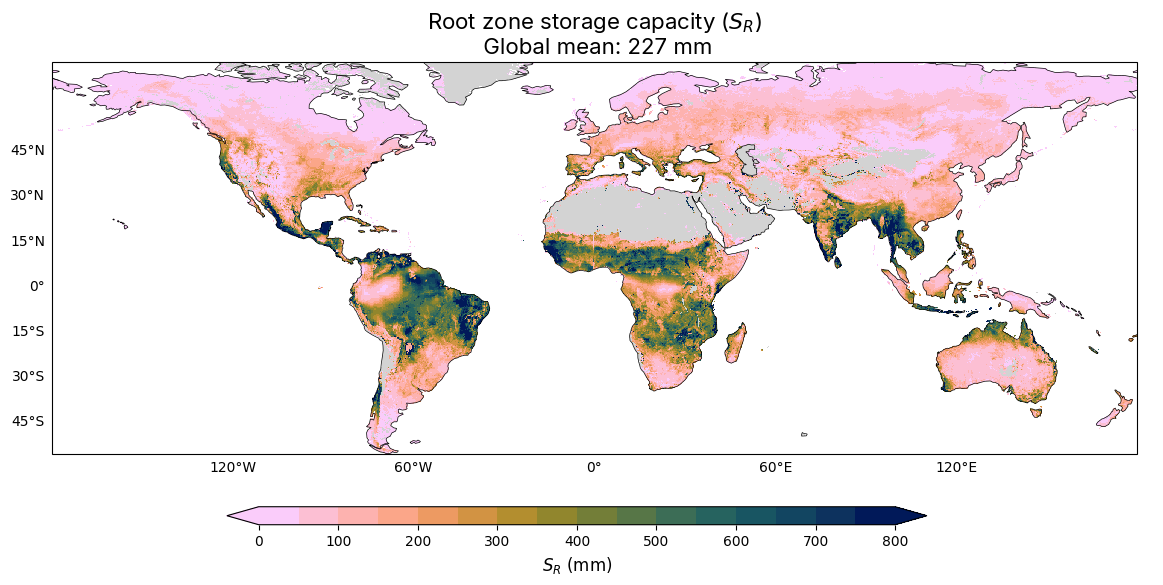

In [5]:
#plt.rcParams['font.family'] = 'Inter'
from cmcrameri import cm
plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree()) # or robinson
daPlot = sr_target.coarsen(lat=4, lon=4).median() # coarsen for faster plotting
# 1. Plot only nans in grey (suppress cbar)
xr.where(daPlot.isnull(), 1, np.nan).plot(
    ax=ax, 
    cmap=colors.ListedColormap(['lightgrey']), 
    vmin=1, 
    vmax=1, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)
#Plot ovean over nans in white
ocean.coarsen(lat=4, lon=4).mean().plot(
    ax=ax, 
    cmap=colors.ListedColormap(['white']),
    vmin=1,
    vmax=1,
    transform=ccrs.PlateCarree(),
    add_colorbar=False
)

# 2. Plot data (store the plot object as 'im' and suppress automatic cbar)
im = daPlot.plot(
    ax=ax, 
    cmap=discrete_colormap(cm.batlow_r, 16), 
    vmin=0, 
    vmax=800, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)

# 3. Create a dedicated axis for the horizontal colorbar below the plot
# Adjust the bottom positioning (0.05) so it doesn't overlap with the latitude labels
cax = plt.gcf().add_axes([0.25, 0.05, 0.5, 0.03]) # [left, bottom, width, height]

# 4. Generate the colorbar horizontally with explicit boundary ticks.
# control width and height of colorbar with cax, and set ticks to match the discrete colormap boundaries
cbar = plt.colorbar(
    im, 
    cax=cax, 
    orientation='horizontal', 
    #fraction=1,
    aspect=30,
    ticks=[0, 100, 200, 300, 400, 500, 600, 700, 800],
    extend='both',
    pad=0.02

)
cbar.set_label('$S_R$ (mm)', size=12)
cbar.ax.tick_params(labelsize=10)

# 5. Add context features
ax.coastlines(linewidth=0.5) # coastlines for context

# 6. Gridlines configuration
lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
lat_ticks = [-45, -30, -15, 0, 15, 30, 45]
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0,
    x_inline=False,
    y_inline=False,
)

# Show only bottom and left labels
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlocator = FixedLocator(lon_ticks)
gl.ylocator = FixedLocator(lat_ticks)
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

abs_pct_deltaSR_mean = global_stats(abs_pct_deltaSR, weighted=True)[0]
ax.set_title(f'Root zone storage capacity ($S_R$)\n Global mean: {global_stats(sr_target, weighted=True)[0]:.0f} mm', font=Inter, fontsize=16)
#plt.savefig("../export/map_deltaSRmm.png", format='png', dpi=300, bbox_inches='tight')
plt.show()

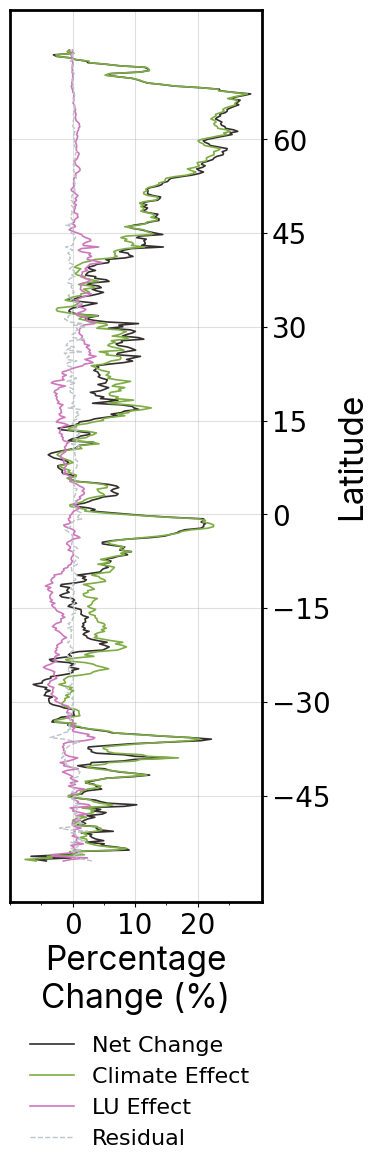

In [11]:
# Plot latitudinal profiles of the deltaSR components
# average across longitude to get latitudinal profiles
# and then plot them on the same plot with different colors for each component.

pct_deltaSRclim_plot = (deltaSR_clim * 100/sr_clim_1901_1930_LU_1901_1930).coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
pct_deltaSR_LU_plot = (deltaSR_LU * 100/sr_clim_1901_1930_LU_1901_1930).coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
pct_deltaSR_interaction_plot = (deltaSR_interaction * 100/sr_clim_1901_1930_LU_1901_1930).coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
pct_deltaSR_plot = (deltaSR_20thC * 100/sr_clim_1901_1930_LU_1901_1930).coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile

c_total = "#342F2D" #"#5E5E5E" # "#190C09" #'blue'# "#292929"
c_clim  = "#7EAC45" # "#3C8EB9" # 'violet' #'#2980b9'
c_lu    = "#CD78BD" # "#A85A4A" #'tan' #"#cf584b"
c_int   = '#bdc3c7'
plt.rcParams.update({'font.size': 14})
fig, ax = plt.subplots(figsize=(4, 12))
# y axis ticks and labels to right side
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.plot(pct_deltaSR_plot.mean(dim='lon'), pct_deltaSR_plot['lat'], label='Net Change', color=c_total, linewidth=1.2)
ax.plot(pct_deltaSRclim_plot.mean(dim='lon'), pct_deltaSRclim_plot['lat'], label='Climate Effect', color=c_clim, linewidth=1.2)
ax.plot(pct_deltaSR_LU_plot.mean(dim='lon'), pct_deltaSR_LU_plot['lat'], label='LU Effect', color=c_lu, linewidth=1.2)
ax.plot(pct_deltaSR_interaction_plot.mean(dim='lon'), pct_deltaSR_interaction_plot['lat'], label='Residual', color=c_int, linestyle='--', linewidth=1)

ax.set_xticks([0, 10, 20])
# minor ticks at -5, 5, 15
ax.set_xticks([-10, -5, 5, 15, 25], minor=True)
ax.set_yticks([-45, -30, -15, 0, 15, 30, 45, 60])
ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_xlabel('Percentage\nChange (%)', font = Inter, fontsize=24)
ax.set_ylabel('Latitude', font = Inter, fontsize=24)
#ax.set_title('Latitudinal Profiles of \n $S_R$ Change Components', font = Inter, fontsize=16)
ax.legend( frameon=False, fontsize=16, loc='lower left',bbox_to_anchor=(0.0, -0.3)) # prop=Inter
ax.grid(which='major', alpha=0.4)
#ax.grid(which='minor', axis='x', alpha=0.2)
# border thickness
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
#plt.savefig("../export/latitudinal_profiles.svg", format='svg', bbox_inches='tight')
plt.tight_layout()
plt.show()

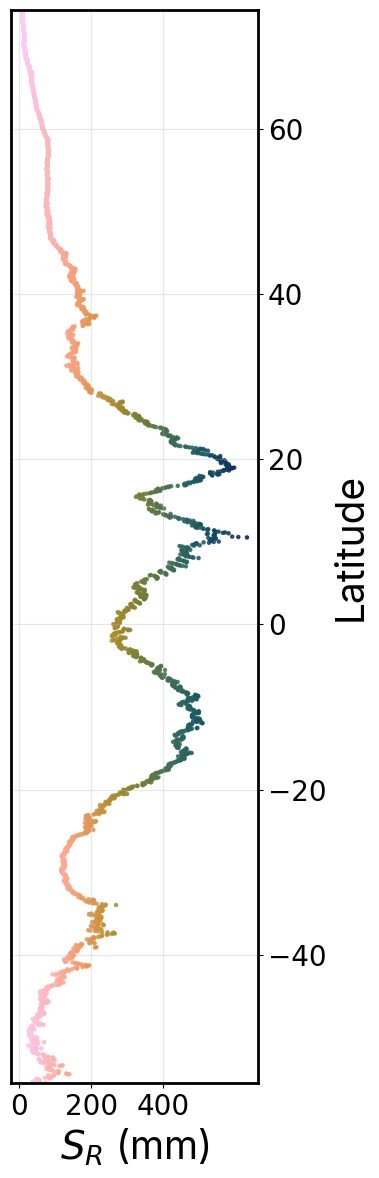

In [71]:
# Plot latitudinal profiles of the deltaSR components
# average across longitude to get latitudinal profiles
# and then plot them on the same plot with different colors for each component.

sr_target_plot = sr_target.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
c_total = "#190C09" #'blue'# "#292929"
c_clim  = "#3C8EB9" # 'violet' #'#2980b9'
c_lu    = "#A85A4A" #'tan' #"#cf584b"
c_int   = '#bdc3c7'
plt.rcParams.update({'font.size': 14})
fig, ax = plt.subplots(figsize=(4, 12))
# y axis ticks and labels to right side
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
#ax.plot(sr_target_plot.mean(dim='lon'), sr_target_plot['lat'], label='Target', color=c_total, linewidth=1.2)
# alternative: color with cm.batlow_r colormap based on the value of sr_target_plot, with darker colors for higher values
ax.scatter(sr_target.mean(dim='lon'), sr_target['lat'], c=sr_target.mean(dim='lon'), cmap=cm.batlow_r, s=5, alpha=0.8)
ax.set_xlabel('$S_R$ (mm)', font = Inter, fontsize=28)
ax.set_ylabel('Latitude', font = Inter, fontsize=28)
ax.set_ylim(sr_target['lat'].min(), sr_target['lat'].max())
# tick labels font size
ax.set_xticks([0, 200,400])
ax.tick_params(axis='both', which='major', labelsize=20)
#ax.set_title('Latitudinal Profiles of \n $S_R$ Change Components', font = Inter, fontsize=16)
#ax.legend(loc='upper left', frameon=True, fontsize=12, prop=Inter) #, bbox_to_anchor=(0.5, 1.2))
ax.grid(alpha=0.3)
# border thickness
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
#plt.savefig("../export/latitudinal_profiles.svg", format='svg', bbox_inches='tight')
plt.tight_layout()
plt.show()

# 2. Climate and LU effects

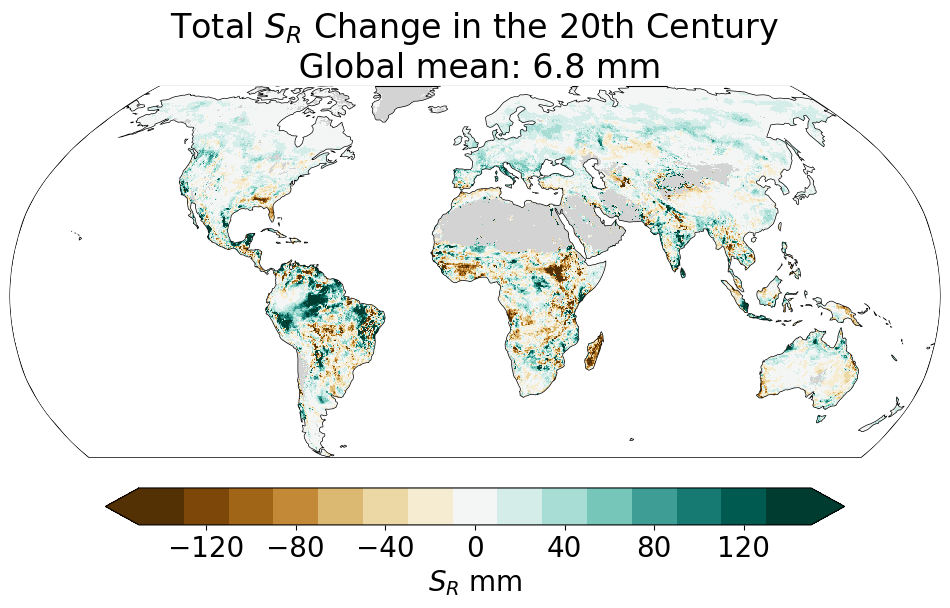

In [7]:
plt.rcParams.update({'font.size': 20})
plot_map(deltaSR_20thC.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Total $S_R$ Change in the 20th Century \n Global mean: {deltaSR_20thC_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label='$S_R$ mm')

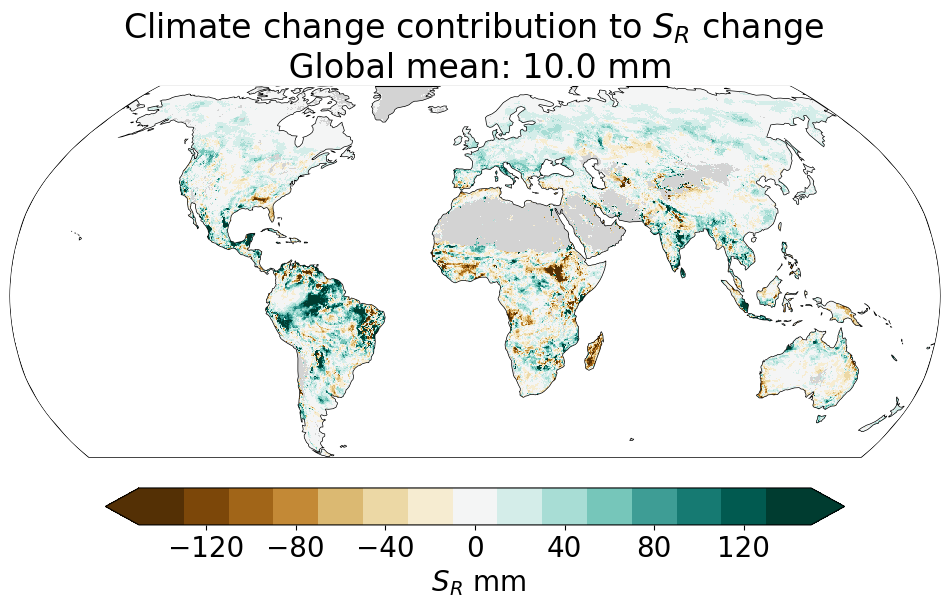

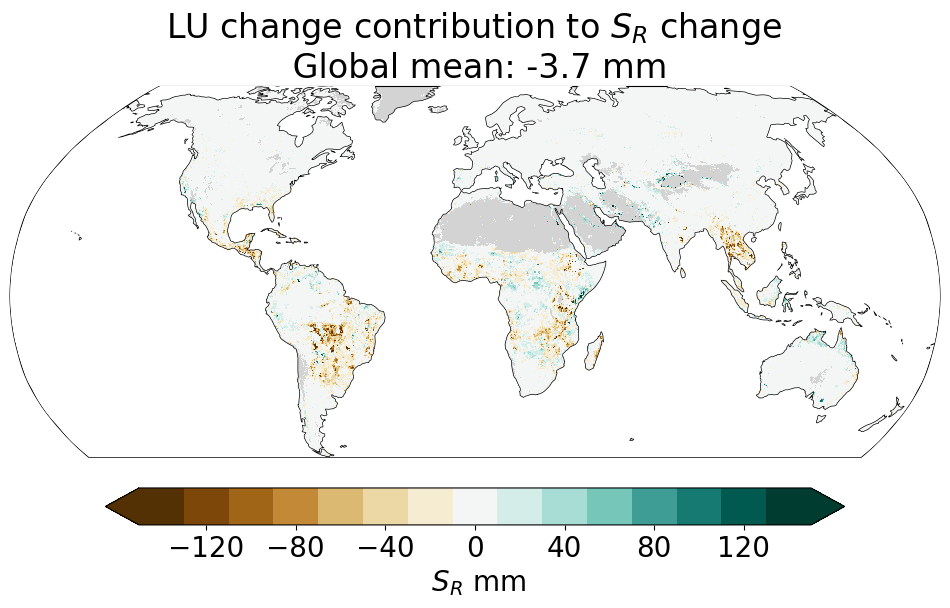

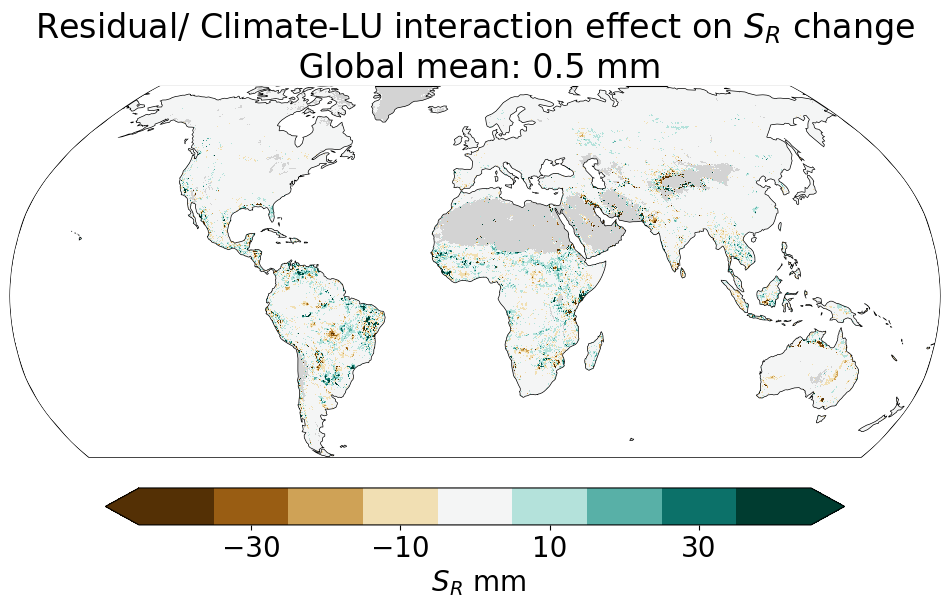

In [8]:
plt.rcParams.update({'font.size': 20})
plot_map(deltaSR_clim.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Climate change contribution to $S_R$ change \n Global mean: {deltaSR_clim_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_LU.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'LU change contribution to $S_R$ change \n Global mean: {deltaSR_LU_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_interaction.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Residual/ Climate-LU interaction effect on $S_R$ change\n Global mean: {deltaSR_interaction_mean:.1f} mm', cmap='BrBG', discrete_cmap = 9, vmin=-45, vmax=45, borders=False, cbar_label=' $S_R$ mm')

# 2.1 Inact and PI change

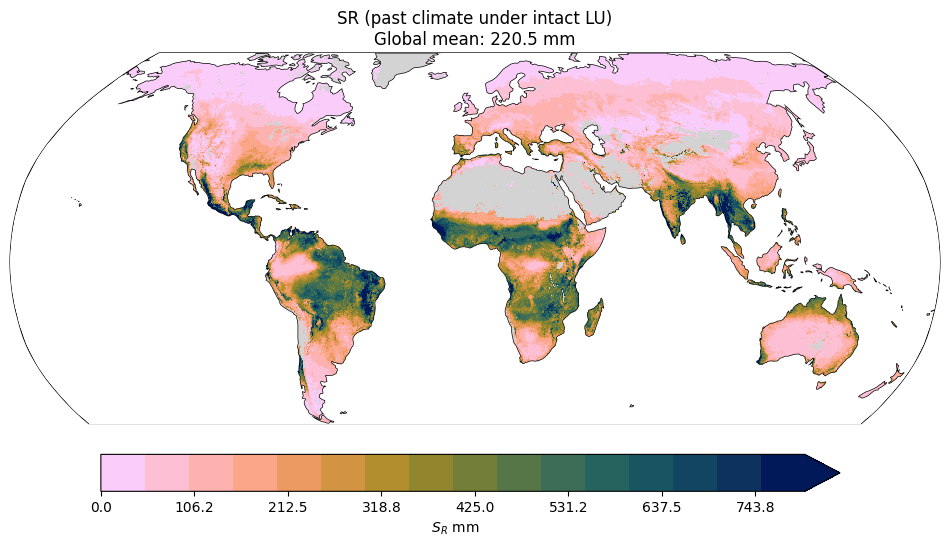

In [15]:
plot_map(sr_clim_1901_1930_LU_1901_1930.coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'SR (past climate under intact LU)\nGlobal mean: {global_stats(sr_clim_1901_1930_LU_1901_1930)[0]:.1f} mm',
         cmap=cm.batlow_r, discrete_cmap = 16, vmin=0, vmax=800, borders=False, cbar_label=' $S_R$ mm')

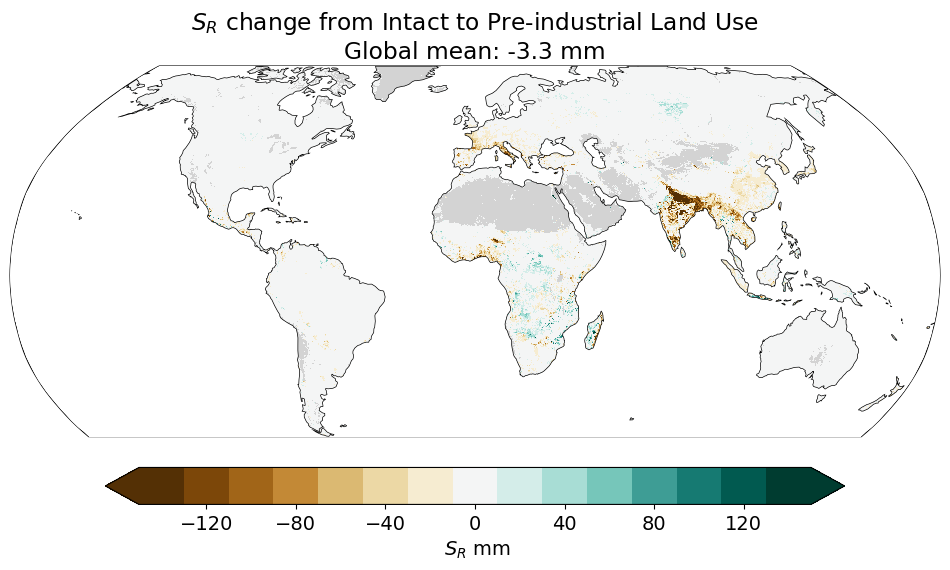

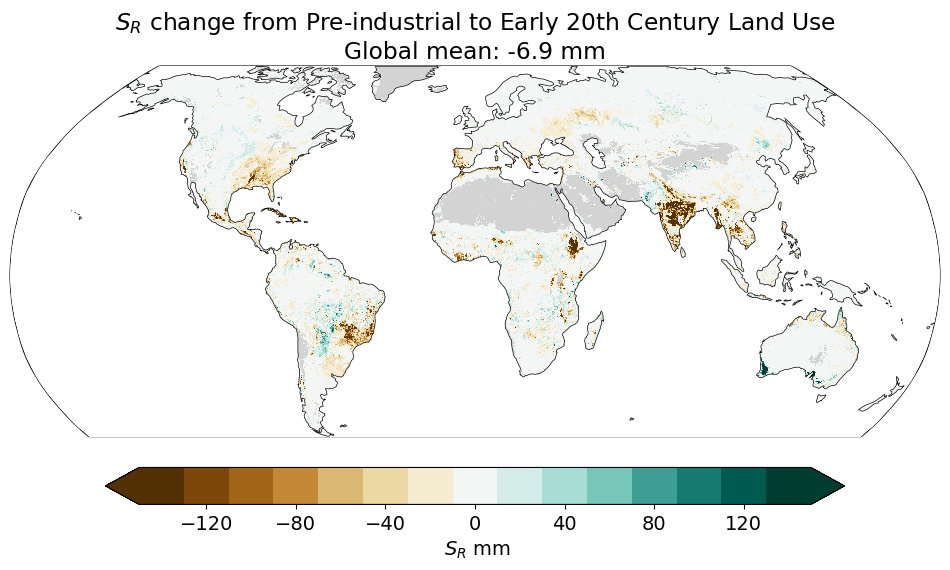

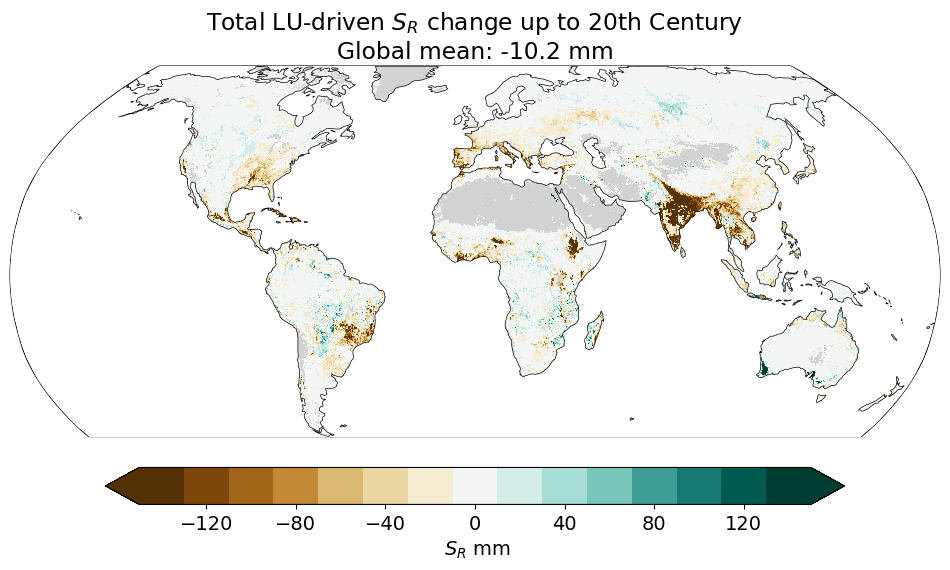

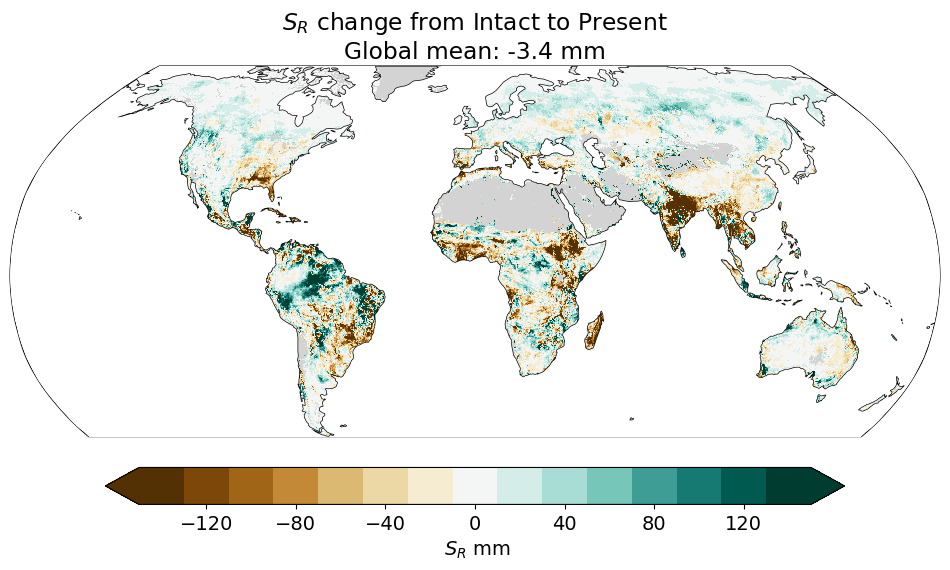

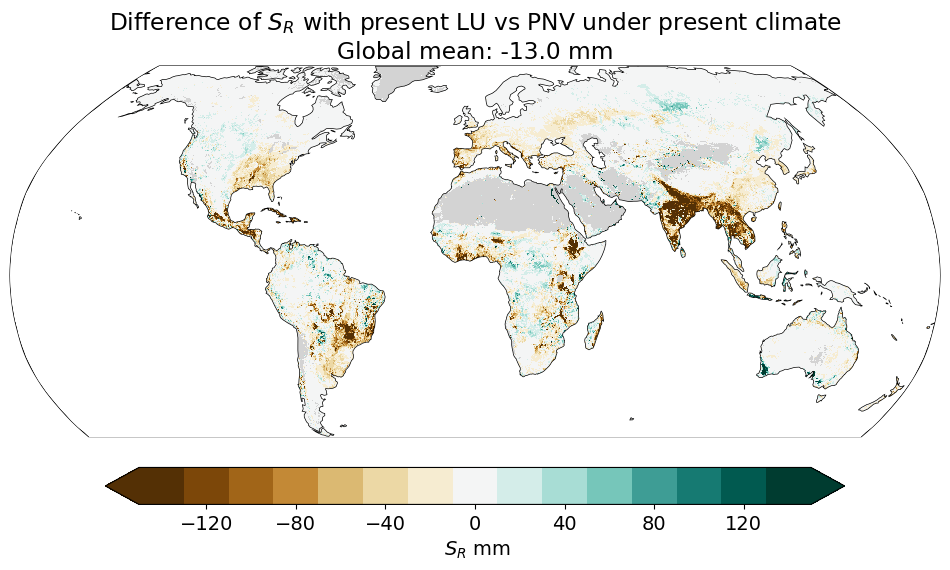

In [111]:
plt.rcParams.update({'font.size': 14})
plot_map(deltaSR_Intact_to_PI.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'$S_R$ change from Intact to Pre-industrial Land Use\nGlobal mean: {deltaSR_Intact_to_PI_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_PI_to_1901.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'$S_R$ change from Pre-industrial to Early 20th Century Land Use\nGlobal mean: {deltaSR_PI_to_1901_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_Intact_to_1901.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'Total LU-driven $S_R$ change up to 20th Century\nGlobal mean: {deltaSR_Intact_to_1901_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_Intact_to_Present.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'$S_R$ change from Intact to Present\nGlobal mean: {deltaSR_Intact_to_Present_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_pnv.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'Difference of $S_R$ with present LU vs PNV under present climate\nGlobal mean: {deltaSR_pnv_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')

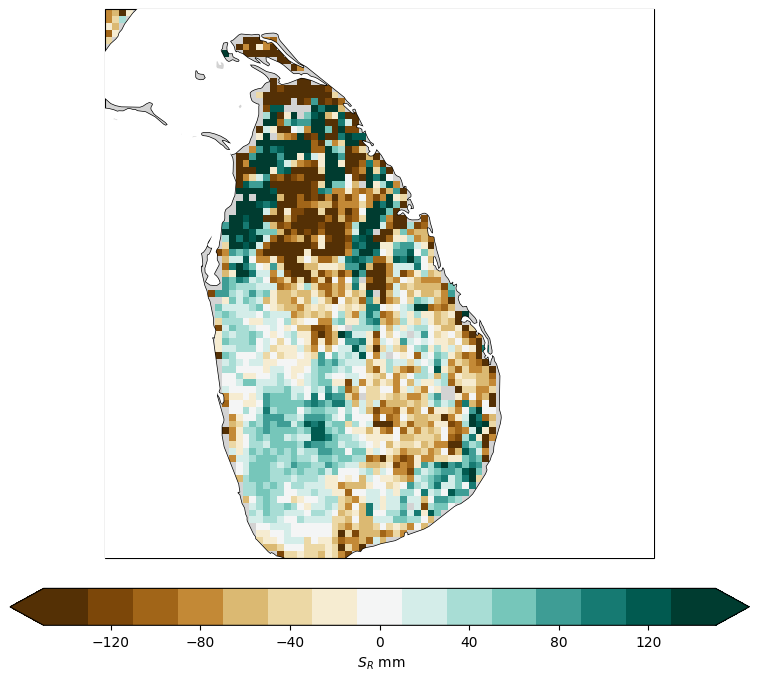

In [22]:
# zoom in
plot_map(deltaSR_pnv.sel(lat=slice(6, 10), lon=slice(79, 83)), vmin=-150, vmax=150,
         cmap='BrBG', discrete_cmap = 15,
         cbar_label=' $S_R$ mm', borders=True, grid_labels=True, local_map=True)

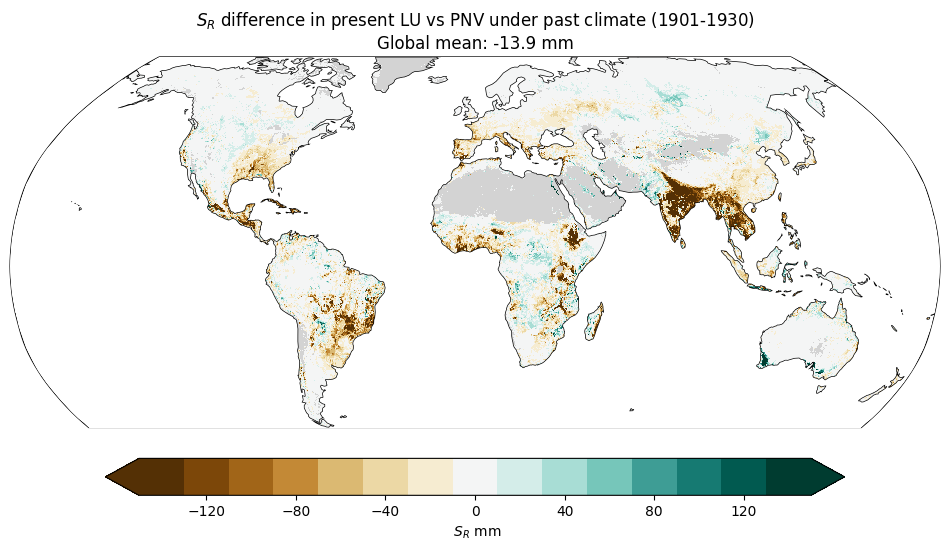

In [6]:
deltaSR_pnv_pastClim = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
plot_map(deltaSR_pnv_pastClim.coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'$S_R$ difference in present LU vs PNV under past climate (1901-1930)\nGlobal mean: {global_stats(deltaSR_pnv_pastClim)[0]:.1f} mm',
         cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')

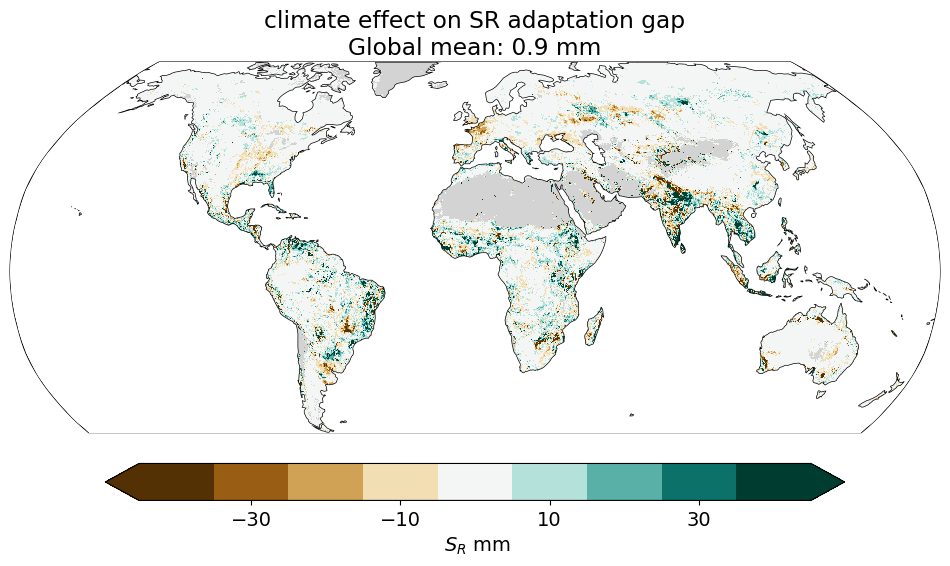

In [118]:
plot_map((deltaSR_pnv - deltaSR_pnv_pastClim).coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'climate effect on SR adaptation gap\nGlobal mean: {global_stats(deltaSR_pnv - deltaSR_pnv_pastClim)[0]:.1f} mm',
         cmap='BrBG', discrete_cmap = 9, vmin=-45, vmax=45, borders=False, cbar_label=' $S_R$ mm')

In [7]:
sr_clim_1931_1960_LU_1901_1930 = preds.sel(climate='1931_1960', lu='1901_1930').sr_k6_mean
deltaSR_clim_1901_1930_to_1931_1960 = sr_clim_1931_1960_LU_1901_1930 - sr_clim_1901_1930_LU_1901_1930

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family ['Inter'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Int

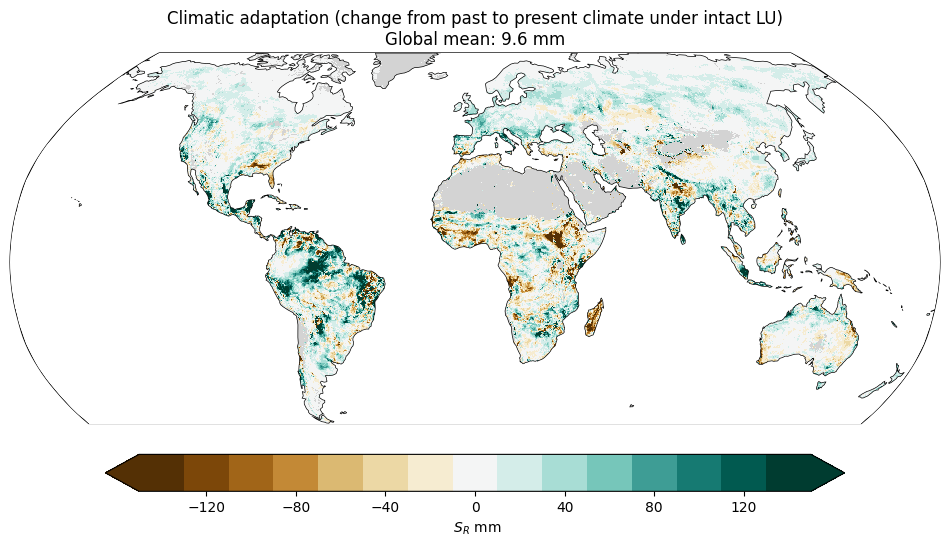

In [11]:
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
climatic_adaptation = sr_clim_1991_2020_LU_Intact - sr_clim_1901_1930_LU_Intact
plot_map(climatic_adaptation.coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'Climatic adaptation (change from past to present climate under intact LU)\nGlobal mean: {global_stats(climatic_adaptation)[0]:.1f} mm',
         cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font f

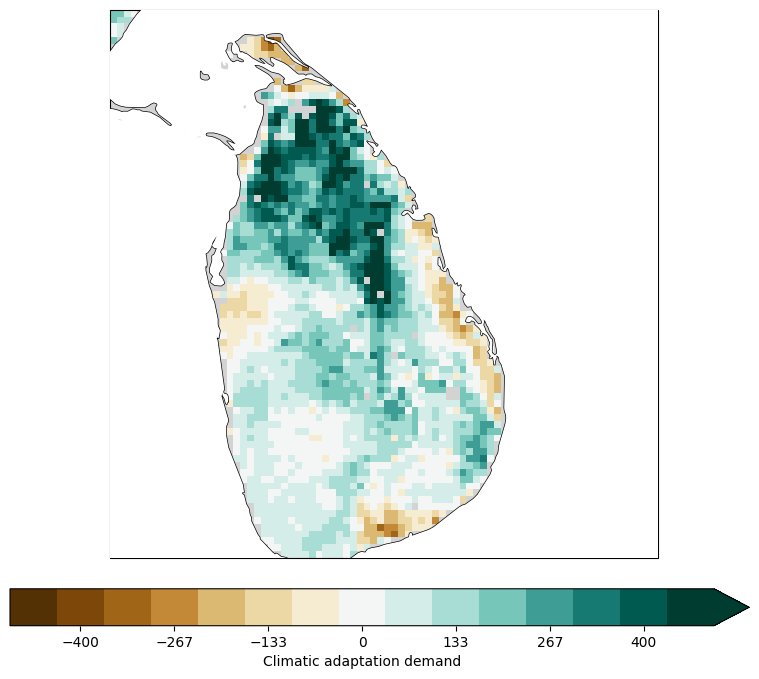

In [25]:
plot_map(climatic_adaptation.sel(lat=slice(6, 10), lon=slice(79, 83)), vmin=-500, vmax=500, cmap='BrBG',
         discrete_cmap = 15, cbar_label='Climatic adaptation demand', borders=True, grid_labels=True, local_map=True)

In [14]:
suppression_rel_to_adaptation_demand = xr.where(climatic_adaptation != 0, deltaSR_pnv / climatic_adaptation, np.nan)

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.


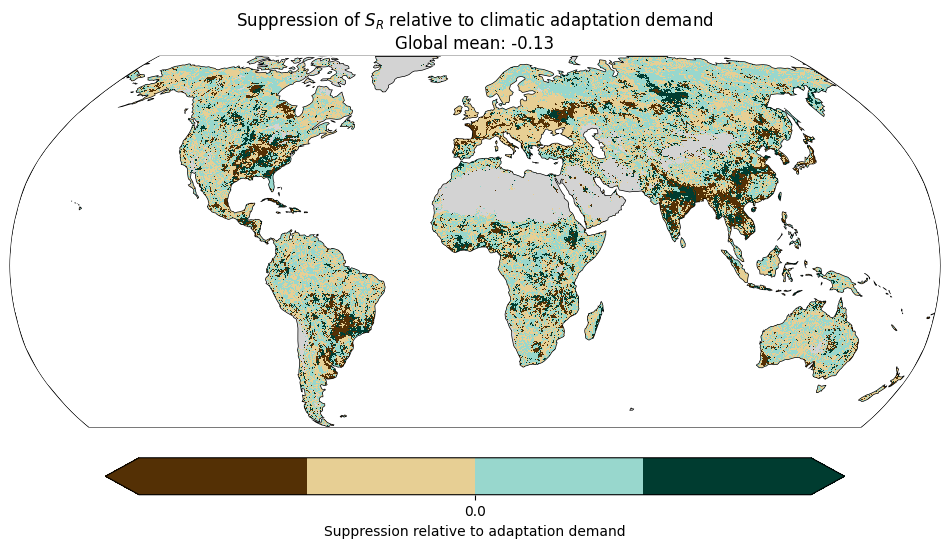

In [16]:
plot_map(suppression_rel_to_adaptation_demand.coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'Suppression of $S_R$ relative to climatic adaptation demand\nGlobal mean: {global_stats(suppression_rel_to_adaptation_demand)[0]:.2f}', 
         cmap='BrBG', discrete_cmap = 4, vmin=-2, vmax=2, borders=False, cbar_label='Suppression relative to adaptation demand')

findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.
findfont: Font family 'Inter' not found.


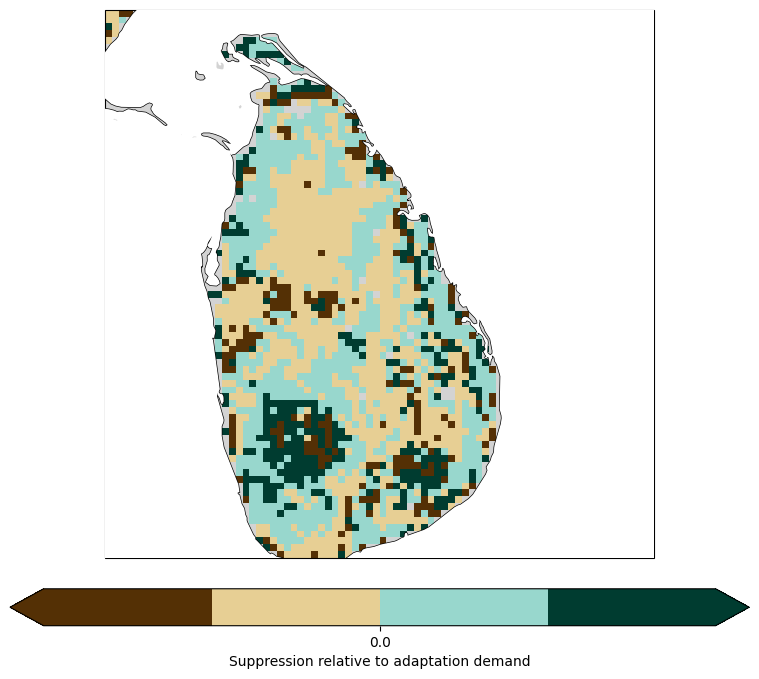

In [22]:
plot_map(suppression_rel_to_adaptation_demand.sel(lat=slice(6, 10), lon=slice(79, 83)), vmin=-2, vmax=2, cmap='BrBG',
         discrete_cmap = 4, cbar_label='Suppression relative to adaptation demand',
         borders=True, grid_labels=True, local_map=True)

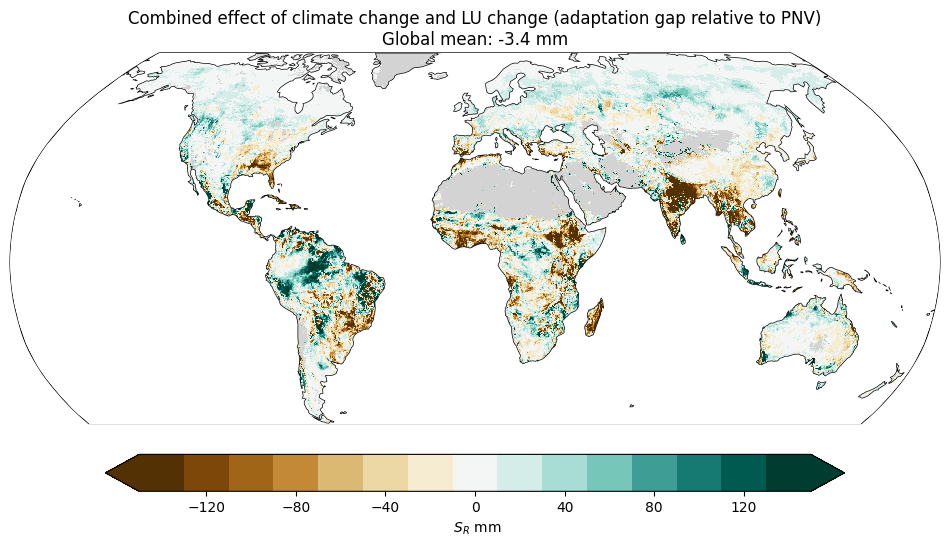

In [11]:
plot_map((deltaSR_pnv + climatic_adaptation).coarsen(dim={'lat': 4, 'lon': 4}).median(),
         title=f'Combined effect of climate change and LU change (adaptation gap relative to PNV)\nGlobal mean: {global_stats(deltaSR_pnv + climatic_adaptation)[0]:.1f} mm',
         cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')

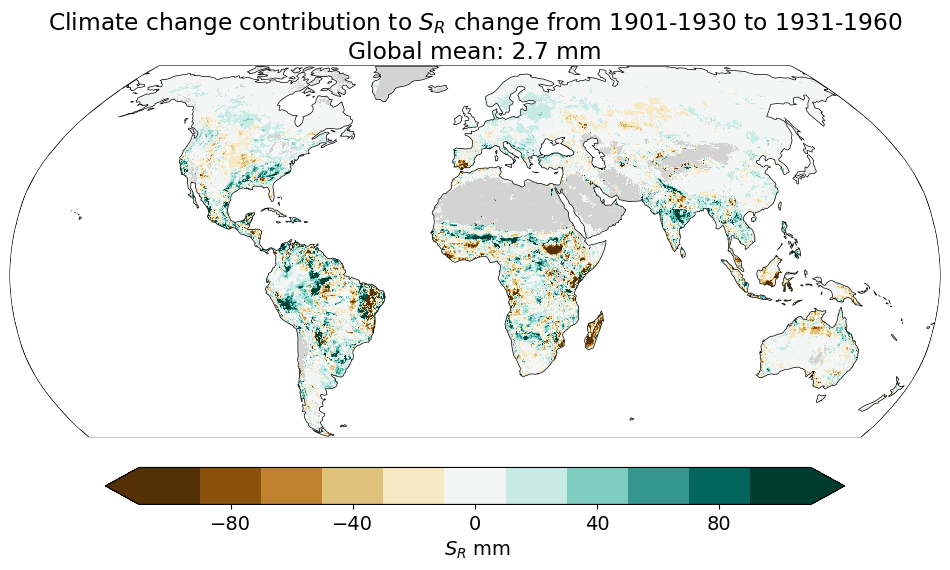

In [109]:
plot_map(deltaSR_clim_1901_1930_to_1931_1960.coarsen(dim={'lat': 4, 'lon': 4}).median(), title=f'Climate change contribution to $S_R$ change from 1901-1930 to 1931-1960\nGlobal mean: {global_stats(deltaSR_clim_1901_1930_to_1931_1960)[0]:.1f} mm', cmap="BrBG", discrete_cmap = 11, vmin=-110, vmax=110, borders=False, cbar_label=' $S_R$ mm')

# 3.1 Change across biomes

In [49]:
# reset rc parameters to default after plotting
plt.rcParams.update(plt.rcParamsDefault)

/tmp/ipykernel_76315/3749354725.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.xtick_labels) #, fontsize=20, , font=Inter


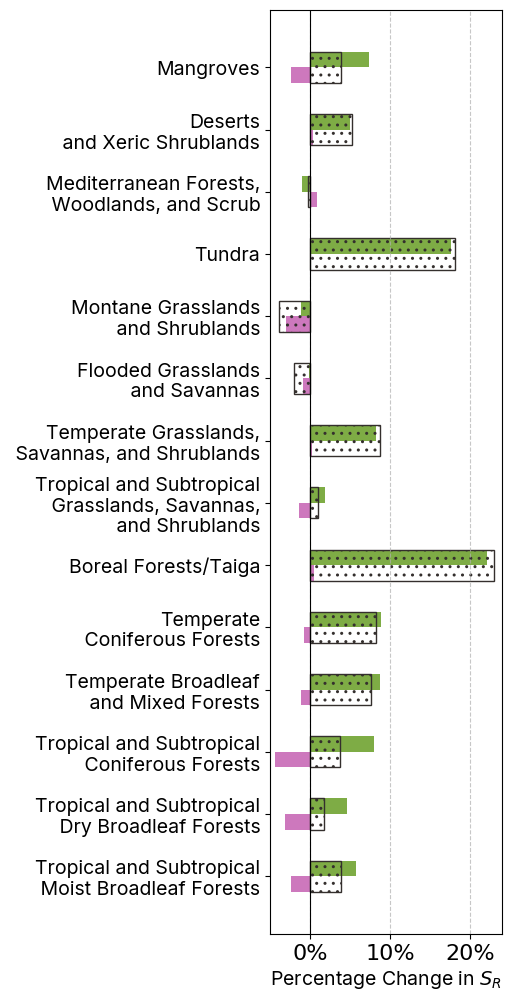

In [66]:
# relative change: biomes
biome_names = {
    1: 'Tropical and Subtropical\n Moist Broadleaf Forests',
    2: 'Tropical and Subtropical\n Dry Broadleaf Forests',
    3: 'Tropical and Subtropical\n Coniferous Forests',
    4: 'Temperate Broadleaf\n and Mixed Forests',
    5: 'Temperate\n Coniferous Forests',
    6: 'Boreal Forests/Taiga',
    7: 'Tropical and Subtropical\n Grasslands, Savannas,\n and Shrublands',
    8: 'Temperate Grasslands,\n Savannas, and Shrublands',
    9: 'Flooded Grasslands\n and Savannas',
    10: 'Montane Grasslands\n and Shrublands',
    11: 'Tundra',
    12: 'Mediterranean Forests,\n Woodlands, and Scrub',
    13: 'Deserts\n and Xeric Shrublands',
    14: 'Mangroves'
}
plt.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(3, 12))

y = np.arange(len(biomeStats))
height = 0.25  # bar 

ax.barh(y + height/2, biomeStats['deltaSR_clim'] / biomeStats['SR_PI'], 
        height=height, color= c_clim, label='Climate-driven Change') #'violet'
ax.barh(y - height/2, biomeStats['deltaSR_LU'] / biomeStats['SR_PI'], 
        height=height, color= c_lu, label='Land Use-driven Change') # tan
ax.barh(y, biomeStats['deltaSR_20thC'] / biomeStats['SR_PI'], 
        height=height * 2, fill=False, hatch = '..', edgecolor= c_total, linewidth=1, label='Net Change') # fill with pattern, blue


# Map biome ids to names for tick labels
tick_labels = [biome_names.get(bid, str(bid)) for bid in biomeStats.index]
ax.set_yticks(y)
ax.set_yticklabels(tick_labels, font=Inter) #, fontsize=14 , 

ax.set_xlim(-0.05, 0.24)
ax.xtick_labels = ['{:.0f}%'.format(x*100) for x in ax.get_xticks()]
ax.set_xticklabels(ax.xtick_labels) #, fontsize=20, , font=Inter
ax.set_xlabel('Percentage Change in $S_R$', fontsize=14, font=Inter)
ax.axvline(0, color='black', linewidth=0.8, linestyle='-')  # zero line
#ax.legend(ncol=1, fontsize=12, frameon=True, loc='lower right') #prop=Inter, bbox_to_anchor=(-0.2, -0.12), ) # font: Inter
ax.grid(axis='x', linestyle='--', alpha=0.7)
plt.yticks(fontsize=14),
#plt.tight_layout()
plt.show()
#plt.savefig("../export/biome_percentage_bar_chart.svg", dpi=300, bbox_inches='tight')

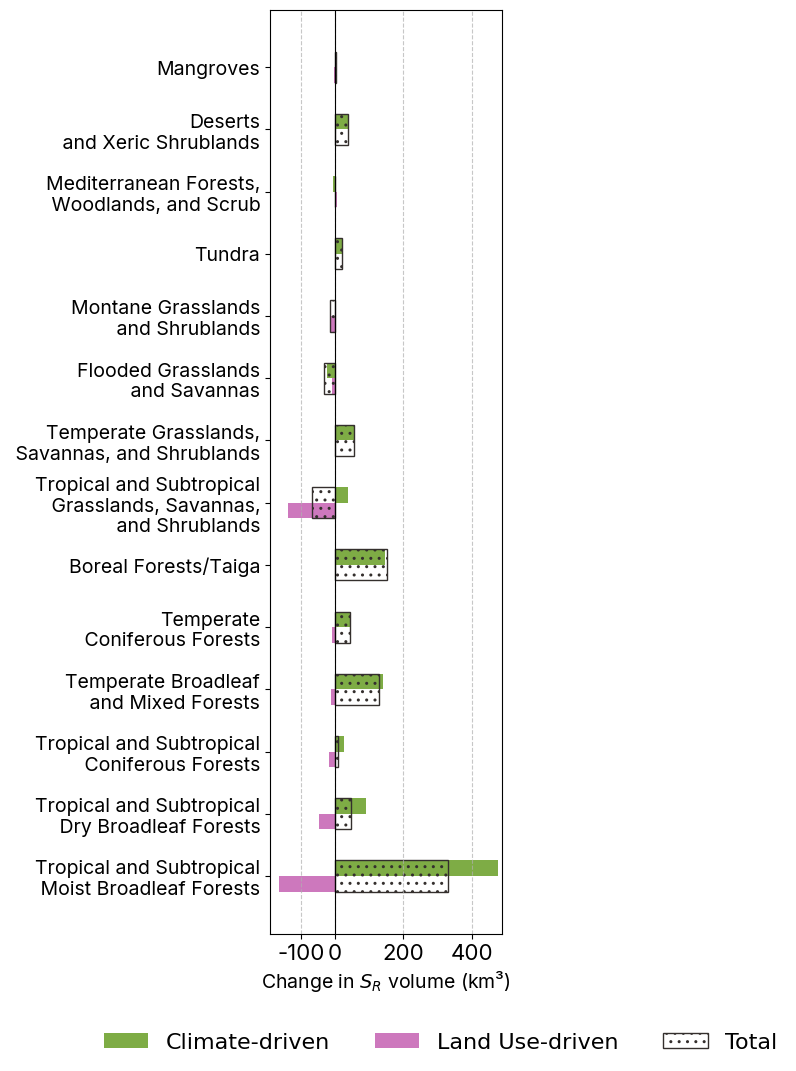

In [81]:
# volume changes: biomes
fig, ax = plt.subplots(figsize=(3, 12))
plt.rcParams.update({'font.size': 16})

y = np.arange(len(biomeStatsVol))
height = 0.25  # bar thickness

ax.barh(y + height/2, biomeStatsVolSum['deltaSR_clim'], 
        height=height, color= c_clim, label='Climate-driven')
ax.barh(y - height/2, biomeStatsVolSum['deltaSR_LU'], 
        height=height, color= c_lu, label='Land Use-driven')
ax.barh(y, biomeStatsVolSum['deltaSR_20thC'], 
        height=height * 2, fill=False, hatch = '..', edgecolor= c_total, linewidth=1, label='Total') # fill with pattern

# Map biome ids to names for tick labels
tick_labels = [biome_names.get(bid, str(bid)) for bid in biomeStatsVol.index]
ax.set_yticks(y)
ax.set_yticklabels(tick_labels, fontsize=16, font=Inter)

ax.set_xlim(-190, 490)
#ax.set_xscale('symlog', linthresh=10)
ax.set_xticks([-100, 0, 200, 400])
ax.xtick_labels = ['{:.0f}'.format(x) for x in ax.get_xticks()]
ax.set_xticklabels(ax.xtick_labels, font=Inter, fontsize=16) #, font=Inter
# x ticklabels line spacing reduced
plt.setp(ax.get_xticklabels(), linespacing=0.5)
ax.set_xlabel('Change in $S_R$ volume (km³)', fontsize=14, font=Inter)
ax.axvline(0, color='black', linewidth=0.8, linestyle='-')  # zero line
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(-0.8, -0.15)) # font: Inter
#ax.legend(ncol=1, fontsize=14, frameon=False, loc='lower left', bbox_to_anchor=(0, -0.2)) # , prop=Inter, 
ax.grid(axis='x', linestyle='--', alpha=0.7)
#plt.tight_layout()
plt.yticks(fontsize=14),
plt.show()
#plt.savefig("../export/biome_Volume_bar_chart.svg", dpi=300, bbox_inches='tight')

# 3.2 aggregate by human LU

In [56]:
# present LU data
lu_1991_2020 = xr.open_dataset('../data/LU_features/1991_2020.nc').interp_like(sr_target, method='nearest')
lu_1901_1930 = xr.open_dataset('../data/LU_features/1901_1930.nc').interp_like(sr_target, method='nearest')
lu_intact = xr.open_dataset('../data/LU_features/intact.nc').interp_like(sr_target, method='nearest')
lu_PI = xr.open_dataset('../data/LU_features/pre-industrial.nc').interp_like(sr_target, method='nearest')

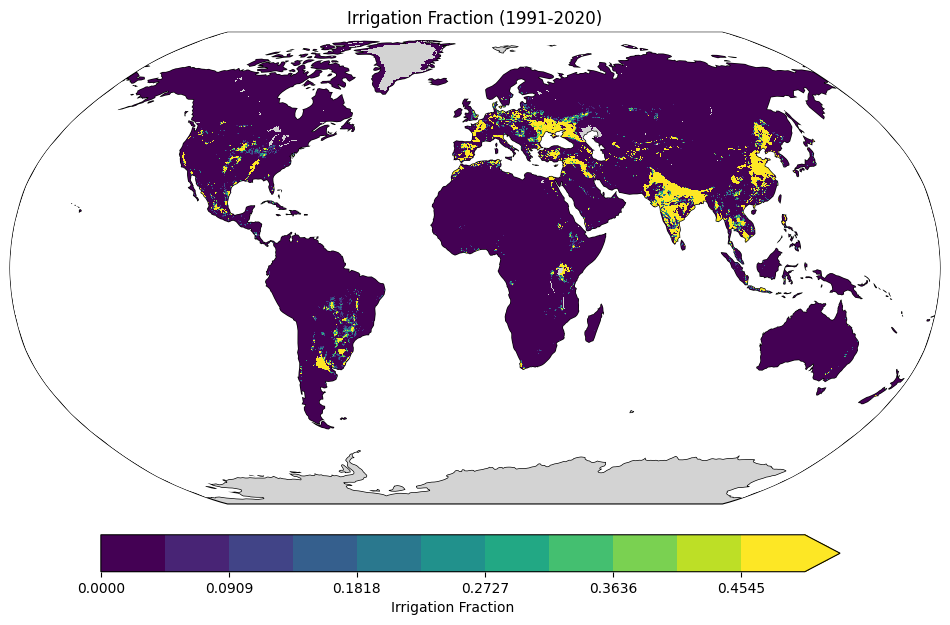

In [17]:
plot_map(lu_1991_2020.irr_frac.coarsen(lat=5, lon=5).median(),
         title='Irrigation Fraction (1991-2020)', cmap='viridis', discrete_cmap=11, vmin=0, vmax=0.5,
         borders=False, cbar_label='Irrigation Fraction')

In [57]:
lu_1991_2020.irr_frac 

<xarray.DataArray 'irr_frac' (lat: 2600, lon: 7200)> Size: 75MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(2600, 7200), dtype=float32)
Coordinates:
  * lat      (lat) float64 21kB -55.58 -55.52 -55.48 ... 74.28 74.33 74.38
  * lon      (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0

In [1]:
deltaSR_pnv

NameError: name 'deltaSR_pnv' is not defined

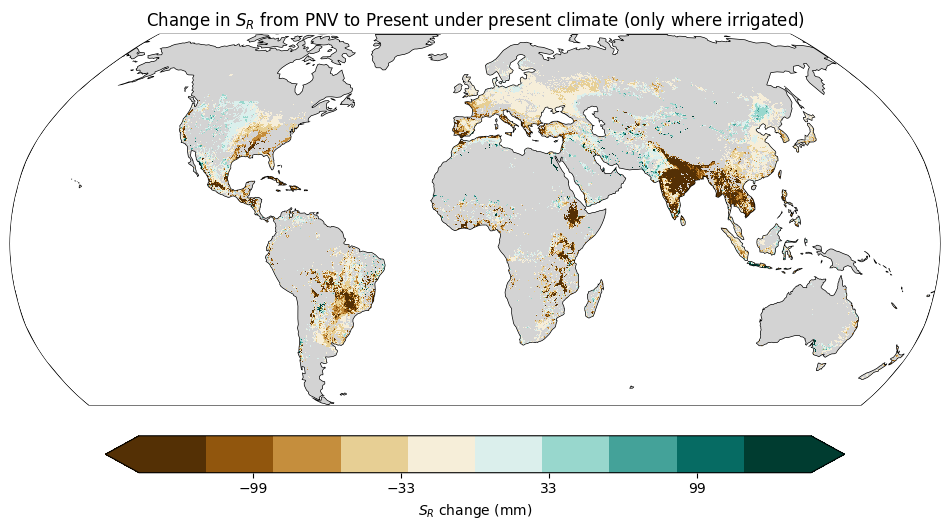

In [ ]:
plot_map(deltaSR_pnv.where(lu_1991_2020.irr_frac > 0).coarsen(lat=4, lon=4).median(),
         vmin=-150, vmax=150, cmap='BrBG', discrete_cmap=10,
         borders=False, cbar_label='$S_R$ change (mm)',
         title='Change in $S_R$ from PNV to Present under present climate (only where irrigated)')

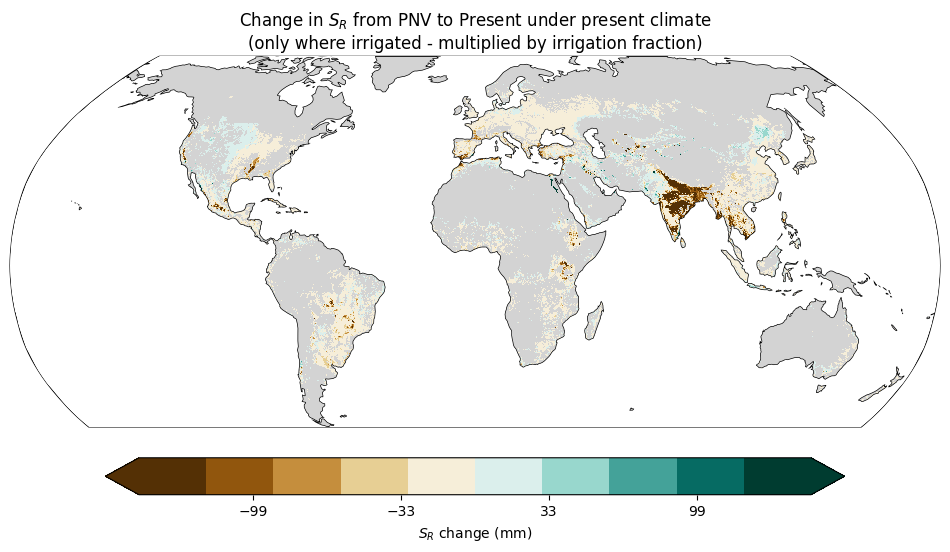

In [90]:
plot_map((deltaSR_pnv.where(lu_1991_2020.irr_frac > 0) * lu_1991_2020.irr_frac).coarsen(lat=4, lon=4).median(),
         vmin=-150, vmax=150, cmap='BrBG', discrete_cmap=10,
         borders=False, cbar_label='$S_R$ change (mm)',
         title='Change in $S_R$ from PNV to Present under present climate\n(only where irrigated - multiplied by irrigation fraction)')

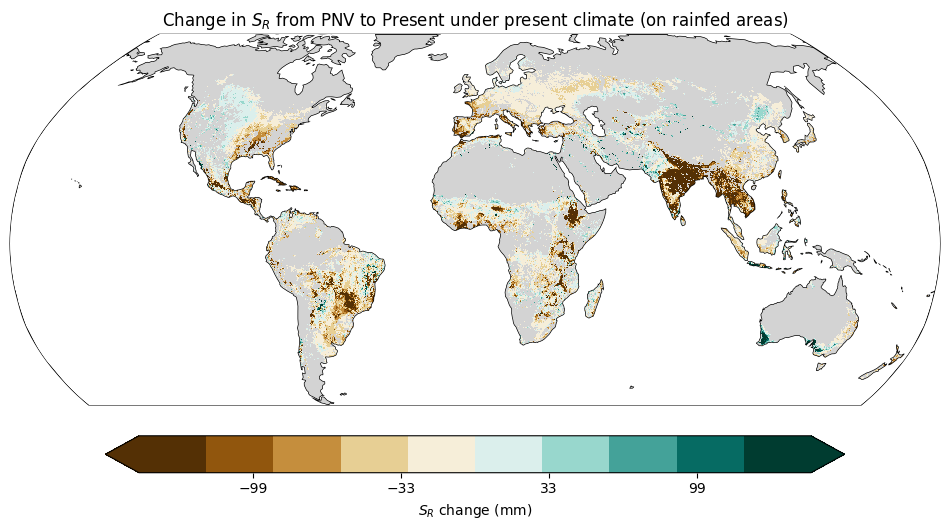

In [66]:
plot_map(deltaSR_pnv.where(lu_1991_2020.rain_frac > 0).coarsen(lat=4, lon=4).median(),
         vmin=-150, vmax=150, cmap='BrBG', discrete_cmap=10,
         borders=False, cbar_label='$S_R$ change (mm)',
         title='Change in $S_R$ from PNV to Present under present climate (on rainfed areas)')

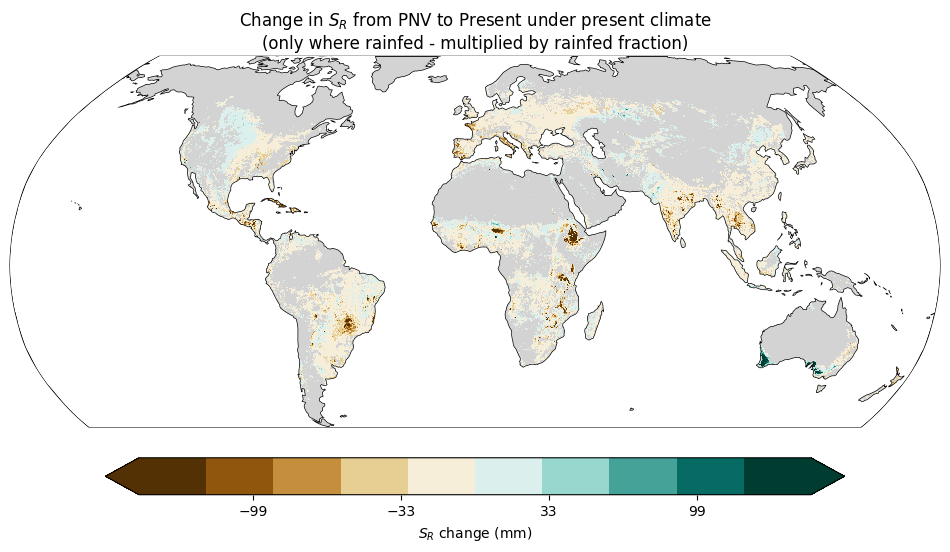

In [92]:
plot_map((deltaSR_pnv.where(lu_1991_2020.rain_frac > 0) * lu_1991_2020.rain_frac).coarsen(lat=4, lon=4).median(),
         vmin=-150, vmax=150, cmap='BrBG', discrete_cmap=10,
         borders=False, cbar_label='$S_R$ change (mm)',
         title='Change in $S_R$ from PNV to Present under present climate\n(only where rainfed - multiplied by rainfed fraction)')

In [15]:
global_stats(deltaSR_20thC.where(synergistic_change))[0].item()

2.610702781571494

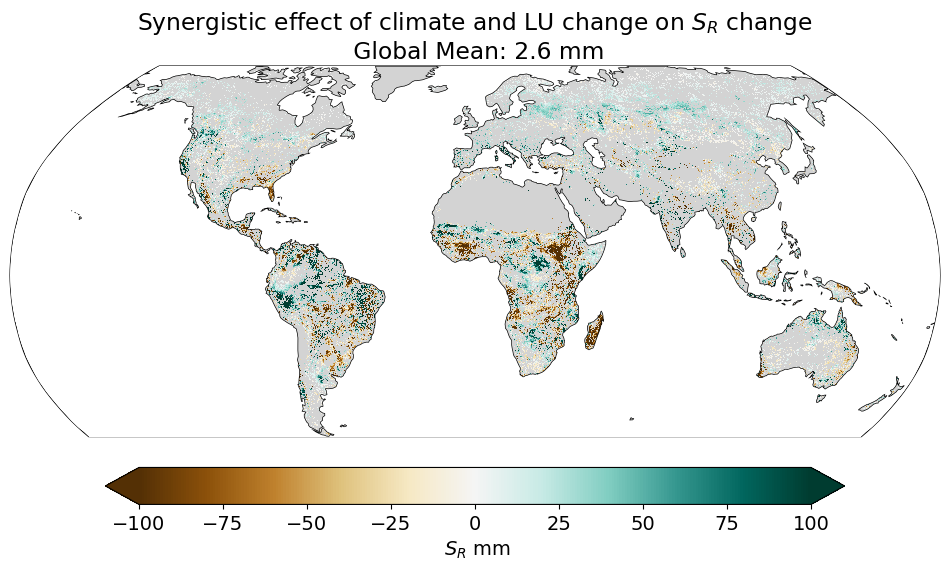

In [17]:
# synergistic effect of climate and LU
# map delta SR where both climate and LU effect are same sign
plot_map(deltaSR_20thC.where(synergistic_change), title=f'Synergistic effect of climate and LU change on $S_R$ change \n Global Mean: {global_stats(deltaSR_20thC.where(synergistic_change))[0].item():.1f} mm', cmap='BrBG', vmin=-100, vmax=100, borders=False, cbar_label=' $S_R$ mm')

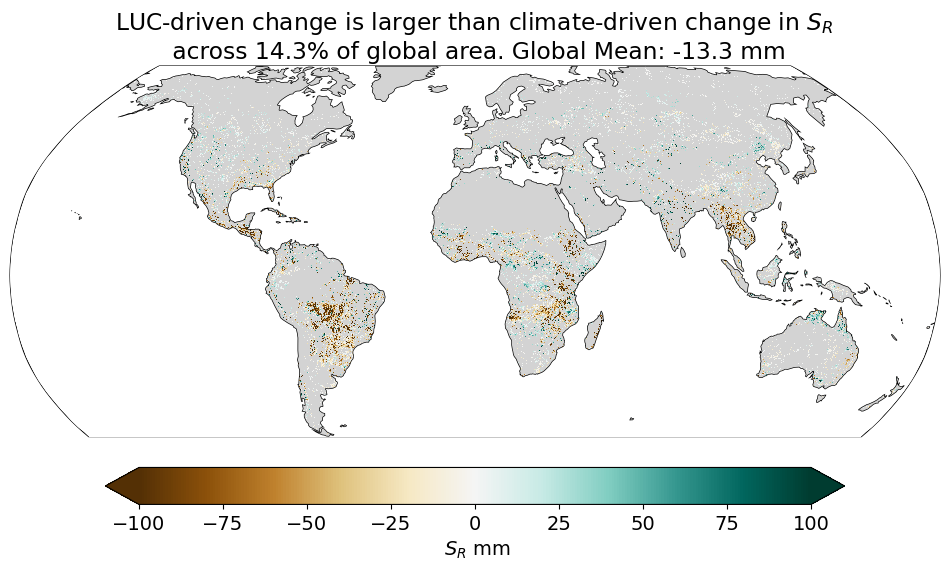

In [18]:
lu_dominant = (np.abs(deltaSR_LU) > np.abs(deltaSR_clim)) & deltaSR_20thC.notnull()
# plot delta SR where lu_dominant
plot_map(deltaSR_20thC.where(lu_dominant), title=f'LUC-driven change is larger than climate-driven change in $S_R$ \n across {lu_dominant.sum() * 100 / deltaSR_20thC.notnull().sum():.1f}% of global area. Global Mean: {global_stats(deltaSR_20thC.where(lu_dominant))[0].item():.1f} mm', cmap='BrBG', vmin=-100, vmax=100, borders=False, cbar_label=' $S_R$ mm')

In [34]:
# get weighted and unweighted global means of all 168 scenarios to a dataframe by applying the global_stats function to each scenario using a loop and store the results in a dataframe with columns for scenario name, mean, and std.
import pandas as pd
scenario_names = []
scenario_means_weighted = []
scenario_stds_weighted = []
scenario_means_unweighted = []
scenario_stds_unweighted = []
climate = []
LU = []
for clim in preds['climate'].values:
    for lu in preds['lu'].values:
        scenario_name = f"{clim}_{lu}"
        climate.append(clim)
        LU.append(lu)
        scenario_names.append(scenario_name)
        da_mean = preds.sel(climate=clim, lu=lu).sr_k6_mean
        #ds_std = preds.sel(climate=clim, lu=lu).sr_k6_std
        mean_w, _ = global_stats(da_mean, weighted=True)
        mean_u, _ = global_stats(da_mean, weighted=False)
        #std_w, _ = global_stats(ds_std, weighted=True)
        #std_u, _ = global_stats(ds_std, weighted=False)
        scenario_means_weighted.append(mean_w.item())
        #scenario_stds_weighted.append(std_w.item())
        scenario_means_unweighted.append(mean_u.item())
        #scenario_stds_unweighted.append(std_u.item())
df_stats = pd.DataFrame({
    'scenario': scenario_names,
    'climate': climate,
    'LU': LU,
    'mean_weighted': scenario_means_weighted,
    #'std_weighted': scenario_stds_weighted,
    'mean_unweighted': scenario_means_unweighted,
    #'std_unweighted': scenario_stds_unweighted
})

In [35]:
# subset the df for plotting
df_statCopy = df_stats.drop(['mean_unweighted'], axis=1) # 'std_weighted',
df_plot = df_statCopy[df_statCopy['LU'] == df_statCopy['climate']]
df_plot = pd.concat([df_plot, df_statCopy[(df_statCopy['LU'] == 'pre-industrial') & (df_statCopy['climate'] == '1901_1930')]], ignore_index=True)
df_plot = pd.concat([df_plot, df_statCopy[(df_statCopy['LU'] == 'intact') & (df_statCopy['climate'] == '1901_1930')]], ignore_index=True)

# add a past vs future column for coloring
df_plot['era'] = df_plot['climate'].apply(lambda x: 'Past' if
                                          x == '1901_1930' or
                                          x == '1931_1960' or 
                                          x == '1961_1990' or
                                          x == '1991_2020' else 'Future')

# overwrite the era for the intact and pre-industrial scenarios
df_plot.loc[df_plot['scenario'] == '1901_1930_intact', 'era'] = 'Intact'
df_plot.loc[df_plot['scenario'] == '1901_1930_pre-industrial', 'era'] = 'PI'

# add a column for ssp for future scenarios
def get_ssp(clim):
    if 'ssp126' in clim:
        return '126'
    elif 'ssp245' in clim:
        return '245'
    elif 'ssp370' in clim:
        return '370'
    elif 'ssp460' in clim:
        return '460'
    else:
        return ''
df_plot['ssp'] = df_plot['climate'].apply(get_ssp)

# add time step value and label columns for plotting
# value: 1 for 1901_1930, 2 for 1931_1960, 3 for 1961_1990, 4 for 1991_2020, 5 2041_2070, 6 for 2071_2099
# label: 1901-1930, 1931-1960, 1961-1990, 1991-2020, 2041-2070, 2071-2099
def get_time_step(clim):
    if clim == '1901_1930':
        return 1, '1901-1930'
    elif clim == '1931_1960':
        return 2, '1931-1960'
    elif clim == '1961_1990':
        return 3, '1961-1990'
    elif clim == '1991_2020':
        return 4, '1991-2020'
    elif clim == '2041_2070_ssp126' or clim == '2041_2070_ssp245' or clim == '2041_2070_ssp370' or clim == '2041_2070_ssp460':
        return 5, '2041-2070'
    elif clim == '2071_2099_ssp126' or clim == '2071_2099_ssp245' or clim == '2071_2099_ssp370' or clim == '2071_2099_ssp460':
        return 6, '2071-2099'
    else:
        return np.nan, ''
df_plot['time_step'], df_plot['time_label'] = zip(*df_plot['climate'].apply(get_time_step))

# add dummy rows to plot the line between the last historical and first future scenario
# 4 rows per SSP, values same as 1991-2020 scenario
dummy_mean = df_plot[(df_plot['climate'] == '1991_2020') & (df_plot['LU'] == '1991_2020')]['mean_weighted'].values[0]
#dummy_std = df_plot[(df_plot['climate'] == '1991_2020') & (df_plot['LU'] == '1991_2020')]['std_weighted'].values[0]

for ssp in ['126', '245', '370', '460']:
    dummy_row = {
        'scenario': 'dummy',
        'climate': '1991_2020',
        'LU': '1991_2020',
        'mean_weighted': dummy_mean,
        #'std_weighted': dummy_std,
        'era': 'Future',
        'ssp': ssp,
        'time_step': 4,
        'time_label': '1991-2020'
    }
    df_plot = pd.concat([df_plot, pd.DataFrame([dummy_row])], ignore_index=True)

df_plot = df_plot.sort_values(['ssp', 'time_step'])
#df_plot = df_plot.sort_values('time_step')

In [36]:
df_plot

,scenario,climate,LU,mean_weighted,era,ssp,time_step,time_label
0,1901_1930_1901_1930,1901_1930,1901_1930,220.506133,Past,,1,1901-1930
12,1901_1930_pre-industrial,1901_1930,pre-industrial,227.365781,PI,,1,1901-1930
13,1901_1930_intact,1901_1930,intact,230.704286,Intact,,1,1901-1930
1,1931_1960_1931_1960,1931_1960,1931_1960,222.427728,Past,,2,1931-1960
2,1961_1990_1961_1990,1961_1990,1961_1990,219.914163,Past,,3,1961-1990
3,1991_2020_1991_2020,1991_2020,1991_2020,227.269051,Past,,4,1991-2020
14,dummy,1991_2020,1991_2020,227.269051,Future,126,4,1991-2020
4,2041_2070_ssp126_2041_2070_ssp126,2041_2070_ssp126,2041_2070_ssp126,240.415290,Future,126,5,2041-2070
8,2071_2099_ssp126_2071_2099_ssp126,2071_2099_ssp126,2071_2099_ssp126,240.253560,Future,126,6,2071-2099
15,dummy,1991_2020,1991_2020,227.269051,Future,245,4,1991-2020
